# Avance 1: Diseño del estudio y relaciones entre variables

**Proyecto:** Determinantes de las hospitalizaciones prolongadas en beneficiarios FONASA (Chile, 2020)

El notebook sigue el orden de la pauta: pregunta de investigación e hipótesis, revisión de literatura, metodología, diagrama metodológico y análisis de relaciones entre variables.

## 1. Pregunta de investigación

Unas pocas hospitalizaciones muy largas ocupan buena parte de las camas. En los egresos FONASA de 2020, las estadías de más de 15 días fueron el 9,4 % de los egresos, pero usaron el 47,1 % de los días-cama (el cálculo está en la sección 5). Si sabemos qué se asocia a esas estadías, es más fácil planificar camas.

> ¿Qué factores clínicos, demográficos y del sistema de salud se asocian con la duración de la estadía y con las estadías prolongadas (más de 15 días) en los egresos FONASA de Chile en 2020?

Consideramos prolongada una estadía de más de 15 días, que es el percentil 90 de la duración.

**Hipótesis general**

- H₀: la duración de la estadía y la ocurrencia de estadías prolongadas no se asocian con los factores clínicos, demográficos ni del sistema de salud.
- H₁: al menos uno de esos factores se asocia con la duración de la estadía o con la ocurrencia de estadías prolongadas.

**Hipótesis específicas**, una por grupo de factores:

| | Factores | H₁ |
|---|---|---|
| H1a | Clínicos: capítulo del diagnóstico (CIE-10), cirugía y condición de egreso | Se asocian a la duración y a la estadía prolongada |
| H1b | Demográficos: edad, sexo, nacionalidad y etnia | Se asocian a la duración y a la estadía prolongada (esperamos más días a mayor edad) |
| H1c | Sistema de salud: tipo de establecimiento y región | Se asocian a la duración y a la estadía prolongada |

## 2. Revisión de literatura

Los Grupos Relacionados por el Diagnóstico (GRD) agrupan a los pacientes según su diagnóstico y procedimiento, porque esas dos cosas explican gran parte de los recursos que consume una hospitalización y de lo que dura (Fetter et al., 1980). Aun así, el diagnóstico no lo explica todo. Freitas et al. (2012) analizaron 9 millones de hospitalizaciones en Portugal y encontraron que la edad y el tipo de hospital seguían asociados a las estadías extremas dentro de un mismo GRD. Por eso no nos quedamos solo con el diagnóstico e incluimos factores del paciente y del establecimiento.

Para modelar la duración, la revisión de Lequertier et al. (2021) muestra que la regresión es el método más usado, y eso respalda usar regresión múltiple en el Avance 2. Hay un problema práctico con bases de este tamaño: con casi un millón de registros casi cualquier diferencia sale significativa. Lin et al. (2013) recomiendan reportar el tamaño del efecto junto al valor-p, y nosotros lo interpretamos con los umbrales de Cohen (1988). Raftery (1995) apunta al mismo problema desde la selección de modelos: con muestras grandes, elegir variables por su valor-p lleva a quedarse con variables que casi no aportan. Propone usar el criterio de información bayesiano (BIC; Schwarz, 1978), que es el que usamos en la sección 5.6 para decidir qué variables entran a la regresión.

En Chile, Olivares-Tirado (2020) estudió las estadías largas, pero solo en adultos mayores. No encontramos un trabajo que mire al mismo tiempo factores clínicos, demográficos y del sistema de salud en el total de egresos FONASA, y tampoco uno sobre 2020, el primer año de la pandemia. Ese es el vacío que cubre este proyecto.

## 3. Metodología

El estudio tiene tres partes. Es descriptivo, porque muestra cómo se distribuye la duración; inferencial, porque contrasta las hipótesis con las pruebas de la sección 5, y predictivo, porque en el Avance 2 ajustaremos modelos de regresión múltiple.

| Aspecto | Detalle |
|---|---|
| Fuente | DEIS-MINSAL, egresos hospitalarios 2020 (datos abiertos) |
| Filtro | Solo FONASA (`PREVISION = 1`) y estadías de hasta 365 días. Quitamos 397 egresos (0,04 %) con más de un año; el máximo es de 16.598 días, unos 45 años, lo que solo puede ser un error de registro |
| Registros | 968.098 egresos, dentro del rango pedido de 700.000 a 1.000.000 |
| Unidad de análisis | El egreso hospitalario |
| Período | Año 2020 |

### Selección de variables

La base trae 18 columnas, y elegimos las variables en dos etapas. En la primera revisamos cada columna con tres condiciones: que su significado esté documentado en el diccionario del DEIS o se pueda verificar con los datos, que varíe entre egresos y que no repita la información de otra columna. Así quedan 9 variables candidatas, además de las dos respuestas:

| Variable | Columna | Tipo | Por qué |
|---|---|---|---|
| Días de estada | `DIAS_ESTADA` | Numérica | Respuesta de la regresión lineal |
| Estadía prolongada | `DIAS_ESTADA` > 15 | Categórica (Sí/No) | Respuesta de la regresión logística |
| Capítulo CIE-10 | `DIAG1` | Categórica (21) | Aproxima la gravedad del caso, porque la base no trae el peso GRD |
| Cirugía | `INTERV_Q` | Categórica (Sí/No) | Distingue casos quirúrgicos de médicos. No está en el diccionario; verificamos su codificación con los datos en la sección 5 |
| Condición de egreso | `CONDICION_EGRESO` | Categórica (vivo/fallecido) | Los casos que terminan en fallecimiento son los más graves |
| Edad | `GRUPO_EDAD` | Numérica (punto medio del tramo) | Más edad, más días (Freitas et al., 2012) |
| Sexo | `SEXO` | Categórica | Variable demográfica básica |
| Nacionalidad | `GLOSA_PAIS_ORIGEN` | Categórica (Chilena/Extranjera) | La incluimos para revisar si la duración cambia según el origen del paciente |
| Etnia | `ETNIA` | Categórica (Sí/No) | La incluimos para revisar si la duración cambia según la pertenencia a un pueblo originario |
| Establecimiento | `PERTENENCIA_ESTABLECIMIENTO_SALUD` | Categórica (Público SNSS/No SNSS) | El tipo de hospital se asocia a estadías largas (Freitas et al., 2012) |
| Región | `REGION_RESIDENCIA` | Categórica (16) | Es la región donde vive el paciente; puede reflejar diferencias de acceso y de oferta de camas |

Las columnas que no pasan la primera etapa son estas:

| Columna | Por qué queda fuera |
|---|---|
| `PREVISION`, `GLOSA_PREVISION`, `ANO_EGRESO` | Después del filtro toman un solo valor |
| `GLOSA_REGION_RESIDENCIA`, `GLOSA_COMUNA_RESIDENCIA` | Son el nombre de un código que ya usamos |
| `COMUNA_RESIDENCIA` | Cada comuna pertenece a una sola región (lo comprobamos en 5.6), así que repite la región con 344 categorías en vez de 16 |
| `DIAG2` | Es la causa externa del diagnóstico. Prácticamente solo aparece en el capítulo S00-T98 (traumatismos), con una V de Cramér de 1,00 contra ese capítulo (5.6) |
| `PROCED` | No está en el diccionario y no logramos verificar qué registra (sección 5) |

En la segunda etapa decidimos cuáles de las 9 candidatas entran a la regresión múltiple. Para eso usamos el BIC, el F parcial y el VIF (sección 5.6).

`CONDICION_EGRESO` se conoce recién al momento del alta, así que no sirve para predecir la duración al ingreso del paciente. La usamos como control de gravedad en un modelo explicativo, que es lo que hace este estudio.

### Modelos propuestos

Para el Avance 2 proponemos dos modelos:

| Modelo | Respuesta | Métricas |
|---|---|---|
| Regresión lineal múltiple | log(días de estada) | R² ajustado, MAE, RMSE |
| Regresión logística múltiple | Estadía prolongada | AUC-ROC, sensibilidad, precisión, F1 |

Usamos el logaritmo porque los días tienen una cola larga (sección 5.1). Como el mínimo es 1 día, el logaritmo está definido en todos los egresos. En la logística no basta con la exactitud (*accuracy*): solo el 9,4 % de los egresos son prolongados, así que un modelo que siempre responda "No" acertaría el 90,6 % de las veces. Separaremos el 70 % de los datos para entrenar y el 30 % para evaluar.

Las limitaciones vienen de la base: no trae peso GRD, hospital ni fechas, la edad viene en tramos y 2020 fue un año atípico por la pandemia.

## 4. Diagrama metodológico

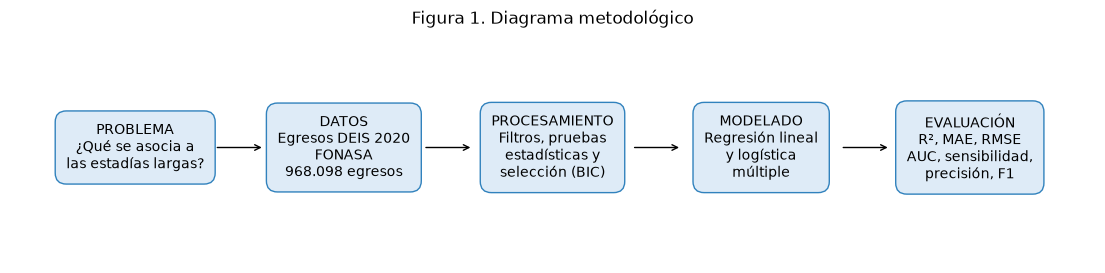

In [1]:
import matplotlib.pyplot as plt

etapas = ["PROBLEMA\n¿Qué se asocia a\nlas estadías largas?",
          "DATOS\nEgresos DEIS 2020\nFONASA\n968.098 egresos",
          "PROCESAMIENTO\nFiltros, pruebas\nestadísticas y\nselección (BIC)",
          "MODELADO\nRegresión lineal\ny logística\nmúltiple",
          "EVALUACIÓN\nR², MAE, RMSE\nAUC, sensibilidad,\nprecisión, F1"]

fig, ax = plt.subplots(figsize=(14, 3))
ax.axis("off")
for i, texto in enumerate(etapas):
    ax.text(i, 0, texto, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.8", facecolor="#deebf7", edgecolor="#3182bd"))
    if i < len(etapas) - 1:
        ax.annotate("", xy=(i + 0.62, 0), xytext=(i + 0.38, 0), arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-0.6, len(etapas) - 0.4)
ax.set_ylim(-1, 1)
ax.set_title("Figura 1. Diagrama metodológico")
plt.show()

## 5. Análisis de relaciones entre variables

### Paso 1: cargar los datos

Leemos el archivo del DEIS directo desde el zip y aplicamos los dos filtros de la metodología: solo FONASA y estadías de hasta 365 días.

In [2]:
import warnings
import zipfile
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore")

with zipfile.ZipFile("data/raw/EGRESOS_2020.zip") as z:
    df = pd.read_csv(z.open("EGRE_DATOS_ABIERTOS_2020.csv"), sep=";", encoding="cp1252", dtype=str)
print("Egresos 2020:", len(df))

df = df[df["PREVISION"] == "1"]                      # solo FONASA
df["dias_estada"] = pd.to_numeric(df["DIAS_ESTADA"])
print("Estadías de más de 365 días:", (df["dias_estada"] > 365).sum(), "| máximo:", df["dias_estada"].max(), "días")
df = df[df["dias_estada"] <= 365].copy()             # quitamos errores de registro
print("Egresos FONASA con estada <= 365 días:", len(df))

Egresos 2020: 1330477


Estadías de más de 365 días: 397 | máximo: 16598 días
Egresos FONASA con estada <= 365 días: 968098


### Paso 2: construir las variables

Transformamos cada columna original en la variable que vamos a usar. Para la edad tomamos el punto medio de cada tramo, y el capítulo CIE-10 lo sacamos del diccionario del DEIS. `CONDICION_EGRESO` viene codificada como 1 = vivo y 2 = fallecido, según el diccionario.

In [3]:
edad_media = {"menor de un año": 0.5, "1 a 9": 5, "10 a 19": 14.5, "20 a 29": 24.5, "30 a 39": 34.5,
              "40 a 49": 44.5, "50 a 59": 54.5, "60 a 69": 64.5, "70 a 79": 74.5, "80 a 89": 84.5,
              "90 y más": 92.5}
cie = pd.read_excel("data/raw/x2020/Diccionario BD egresos hospitalario.xlsx", "codigo CIE-10", header=8)
cie.columns = cie.columns.str.strip()

df["prolongada"] = np.where(df["dias_estada"] > 15, "Sí", "No")
df["edad"] = df["GRUPO_EDAD"].map(edad_media)
df["tramo_edad"] = df["GRUPO_EDAD"]
df["sexo"] = df["SEXO"]
df["nacionalidad"] = df["GLOSA_PAIS_ORIGEN"]
df["etnia"] = np.where(df["ETNIA"].str.startswith("Si"), "Sí", "No")
df["capitulo"] = df["DIAG1"].map(dict(zip(cie["CODIGO SUBCATEGORIA"], cie["CAPITULO"])))
df["capitulo"] = df["capitulo"].fillna(df["DIAG1"].str[:3].map(dict(zip(cie["CODIGO CATEGORIA"], cie["CAPITULO"]))))
df["cirugia"] = df["INTERV_Q"].map({"1": "Sí", "2": "No"})
df["fallecido"] = df["CONDICION_EGRESO"].map({"1": "No", "2": "Sí"})
df["establecimiento"] = np.where(df["PERTENENCIA_ESTABLECIMIENTO_SALUD"].str.startswith("Pert"), "SNSS", "No SNSS")
df["region"] = df["GLOSA_REGION_RESIDENCIA"]

variables = ["dias_estada", "prolongada", "edad", "sexo", "nacionalidad", "etnia",
             "capitulo", "cirugia", "fallecido", "establecimiento", "region"]
print("Valores faltantes:", df[variables].isna().sum().sum())
df[variables].head()

Valores faltantes: 0


,dias_estada,prolongada,edad,sexo,nacionalidad,etnia,capitulo,cirugia,fallecido,establecimiento,region
0,1,No,5.0,HOMBRE,Chileno,No,Q00-Q99,Sí,No,No SNSS,De Tarapacá
1,1,No,5.0,HOMBRE,Chileno,No,Q00-Q99,Sí,No,No SNSS,De Tarapacá
2,1,No,5.0,HOMBRE,Chileno,No,Z00-Z99,Sí,No,No SNSS,De Tarapacá
3,1,No,5.0,HOMBRE,Chileno,No,N00-N99,Sí,No,No SNSS,De Tarapacá
4,1,No,5.0,HOMBRE,Chileno,No,N00-N99,Sí,No,No SNSS,De Tarapacá


`INTERV_Q` y `PROCED` no aparecen en el diccionario del DEIS, así que revisamos con los datos qué registran. Si `INTERV_Q = 1` significa cirugía, debería estar en casi todas las cesáreas y apendicitis y en casi ningún parto normal:

In [4]:
diagnosticos = {"Cesárea (O82)": "O82", "Apendicitis (K35)": "K35", "Colelitiasis (K80)": "K80", "Parto normal (O80)": "O80"}
filas = []
for nombre, codigo in diagnosticos.items():
    grupo = df[df["DIAG1"].str[:3] == codigo]
    filas.append({"diagnóstico": nombre, "egresos": len(grupo),
                  "% INTERV_Q = 1": round(100 * (grupo["INTERV_Q"] == "1").mean(), 1),
                  "% PROCED = 1": round(100 * (grupo["PROCED"] == "1").mean(), 1)})
pd.DataFrame(filas)

,diagnóstico,egresos,% INTERV_Q = 1,% PROCED = 1
0,Cesárea (O82),48185,97.2,3.5
1,Apendicitis (K35),23298,91.2,3.6
2,Colelitiasis (K80),32118,76.0,10.9
3,Parto normal (O80),48208,3.2,41.2


`INTERV_Q = 1` aparece en el 97 % de las cesáreas y en el 91 % de las apendicitis, y solo en el 3 % de los partos normales. Calza con una intervención quirúrgica, así que la usamos como cirugía. Con `PROCED` no pasa lo mismo: vale 1 en el 41 % de los partos normales y en apenas el 4 % de las cesáreas, y no encontramos documentación que diga qué procedimiento registra. Como no podríamos interpretar su efecto, la dejamos fuera.

Ahora vemos cómo se distribuye la duración y cuánto pesan las estadías prolongadas.

In [5]:
largas = df["prolongada"] == "Sí"
print("Media de días:", round(df["dias_estada"].mean(), 1))
print("Mediana de días:", df["dias_estada"].median())
print("Percentil 90:", df["dias_estada"].quantile(0.9))
print("% de egresos prolongados:", round(100 * largas.mean(), 1))
print("% de días-cama que usan:", round(100 * df.loc[largas, "dias_estada"].sum() / df["dias_estada"].sum(), 1))

Media de días: 6.7
Mediana de días: 3.0
Percentil 90: 15.0
% de egresos prolongados: 9.4
% de días-cama que usan: 47.1


La mediana es de 3 días y la media, de 6,7. Que la media sea más del doble de la mediana ya muestra una cola larga a la derecha. El 9,4 % de los egresos son prolongados y usan el 47,1 % de los días-cama.

En toda la sección 5 usamos α = 0,05. Como casi todo va a salir significativo con este tamaño de muestra, para interpretar cada prueba miramos también el tamaño del efecto, con los umbrales de Cohen (1988):

| Medida | Pequeño | Mediano | Grande |
|---|---|---|---|
| ρ de Spearman, r, V de Cramér | 0,1 | 0,3 | 0,5 |
| ε² (Kruskal-Wallis) | 0,01 | 0,06 | 0,14 |

Para ε² usamos como referencia los umbrales que Cohen propone para η², que es la medida equivalente en el ANOVA.

En total hacemos 20 pruebas de asociación. Con la corrección de Bonferroni el nivel quedaría en 0,05 / 20 = 0,0025, y todas las pruebas tienen p < 0,0002, así que la corrección no cambia ninguna decisión.

Cuando un valor-p aparece como 0 o con un exponente muy negativo (por ejemplo, e-98), lo reportamos como p < 0,001.

### 5.1 Pruebas de normalidad

Antes de elegir las pruebas revisamos si las dos variables numéricas, días de estada y edad, siguen una distribución normal.

- H₀: la variable es normal.
- H₁: la variable no es normal.

Usamos Shapiro-Wilk, Kolmogorov-Smirnov con corrección de Lilliefors y Anderson-Darling. Shapiro-Wilk se aplica a una muestra de 5.000 egresos, porque con más datos su valor-p deja de ser exacto.

In [6]:
resultados = []
for var in ["dias_estada", "edad"]:
    x = df[var].astype(float)
    sw = stats.shapiro(x.sample(5000, random_state=1))
    ks_d, ks_p = lilliefors(x, pvalmethod="approx")
    ad = stats.anderson(x, dist="norm")
    resultados.append({"variable": var,
                       "Shapiro-Wilk W": sw.statistic, "p SW": sw.pvalue,
                       "Lilliefors D": ks_d, "p KS": ks_p,
                       "Anderson-Darling A²": ad.statistic, "valor crítico AD 5 %": ad.critical_values[2]})
pd.DataFrame(resultados).round(3)

,variable,Shapiro-Wilk W,p SW,Lilliefors D,p KS,Anderson-Darling A²,valor crítico AD 5 %
0,dias_estada,0.442,0.0,0.328,0.0,150920.967,0.752
1,edad,0.957,0.0,0.129,0.0,13546.111,0.752


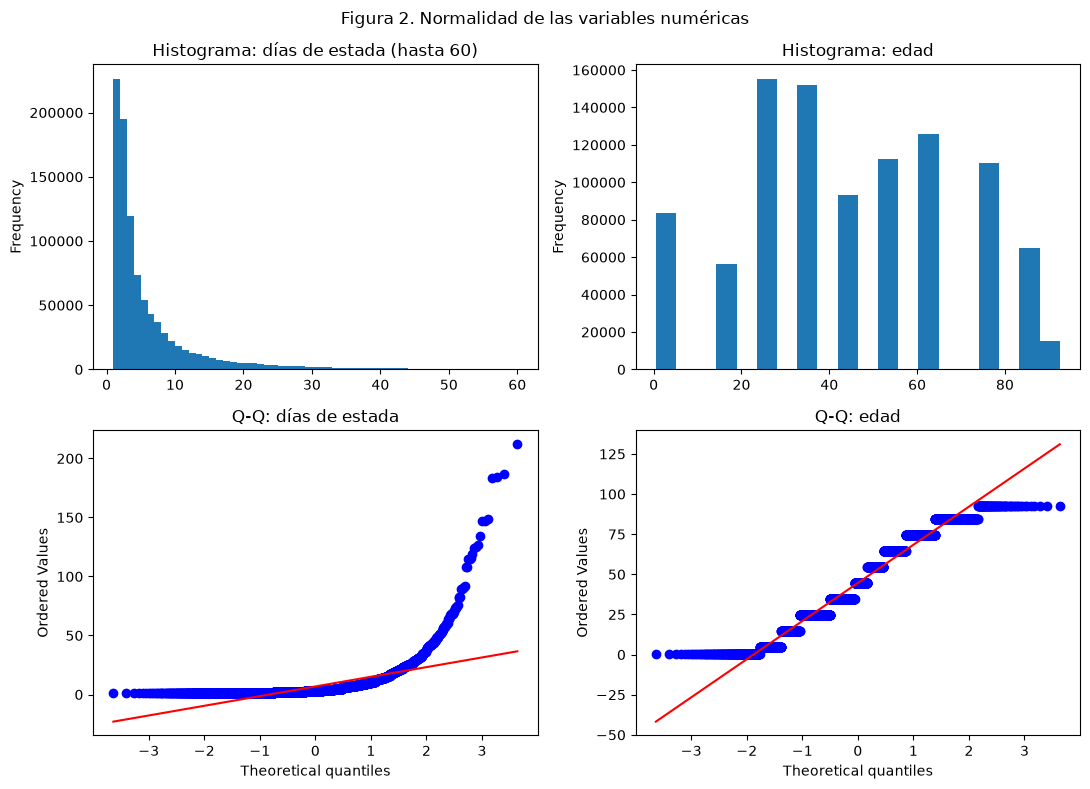

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
df["dias_estada"].plot(kind="hist", bins=range(1, 61), ax=ax[0, 0], title="Histograma: días de estada (hasta 60)")
df["edad"].plot(kind="hist", bins=20, ax=ax[0, 1], title="Histograma: edad")
stats.probplot(df["dias_estada"].sample(5000, random_state=1), plot=ax[1, 0])
ax[1, 0].set_title("Q-Q: días de estada")
stats.probplot(df["edad"].sample(5000, random_state=1), plot=ax[1, 1])
ax[1, 1].set_title("Q-Q: edad")
fig.suptitle("Figura 2. Normalidad de las variables numéricas")
plt.tight_layout()
plt.show()

Las tres pruebas dan p < 0,001 y el estadístico de Anderson-Darling supera su valor crítico, así que rechazamos la normalidad en las dos variables. Los días tienen una cola larga a la derecha, que en el gráfico Q-Q se ve como puntos que se alejan de la recta en la parte alta. La edad viene en tramos, y por eso su Q-Q forma escalones.

Como no se cumple el supuesto, desde aquí usamos pruebas no paramétricas: Spearman en vez de Pearson, Mann-Whitney en vez de t de Student y Kruskal-Wallis en vez de ANOVA.

### 5.2 Numérica vs. numérica: edad y días de estada

Sin normalidad, la prueba que corresponde es la correlación de Spearman.

- H₀: ρ = 0 (no hay relación).
- H₁: ρ ≠ 0.

rho de Spearman: 0.25 | valor-p: 0.0


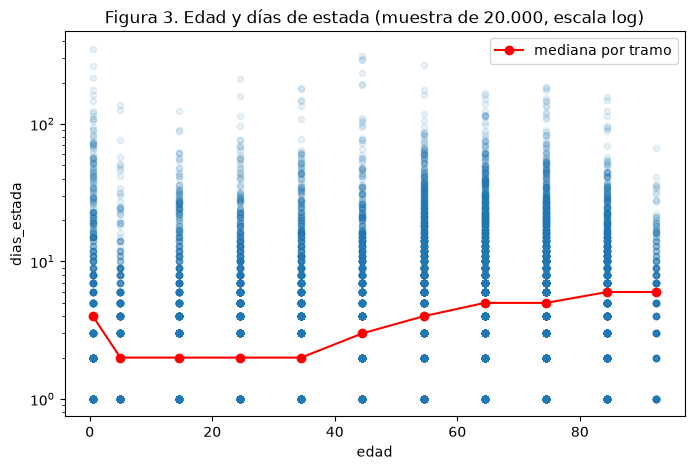

In [8]:
rho, p = stats.spearmanr(df["edad"], df["dias_estada"])
print("rho de Spearman:", round(rho, 3), "| valor-p:", p)

muestra = df.sample(20000, random_state=1)
ax = muestra.plot(kind="scatter", x="edad", y="dias_estada", alpha=0.1, logy=True, figsize=(8, 5))
df.groupby("edad")["dias_estada"].median().plot(ax=ax, color="red", marker="o", label="mediana por tramo")
ax.legend()
ax.set_title("Figura 3. Edad y días de estada (muestra de 20.000, escala log)")
plt.show()

Obtenemos ρ = 0,25 con p < 0,001, así que rechazamos H₀. A mayor edad la estadía tiende a ser más larga, aunque el efecto es pequeño. La línea roja muestra que la mediana sube de 2 días en adultos jóvenes a 6 días desde los 80 años. La excepción son los menores de un año, con una mediana de 4 días.

### 5.3 Numérica vs. categórica: días de estada según cada factor

Como los días no son normales, para los factores de dos grupos usamos Mann-Whitney U, con la correlación biserial de rangos *r* como tamaño del efecto (Kerby, 2014). Para los de más de dos grupos usamos Kruskal-Wallis, con ε².

- H₀: los días se distribuyen igual en todos los grupos del factor.
- H₁: al menos un grupo es distinto.

In [9]:
filas = []
for var in ["sexo", "nacionalidad", "etnia", "cirugia", "fallecido", "establecimiento"]:
    g1, g2 = sorted(df[var].unique())
    x1 = df.loc[df[var] == g1, "dias_estada"]
    x2 = df.loc[df[var] == g2, "dias_estada"]
    u, p = stats.mannwhitneyu(x1, x2)
    r = 2 * u / (len(x1) * len(x2)) - 1              # r > 0: el grupo 1 tiene estadías más largas
    filas.append({"variable": var, "prueba": "Mann-Whitney", "grupos": f"{g1} / {g2}",
                  "medianas": f"{x1.median():.0f} / {x2.median():.0f}", "valor-p": p, "efecto": round(r, 2)})

for var in ["capitulo", "region"]:
    grupos = [g["dias_estada"] for _, g in df.groupby(var)]
    h, p = stats.kruskal(*grupos)
    medianas = df.groupby(var)["dias_estada"].median()
    filas.append({"variable": var, "prueba": "Kruskal-Wallis", "grupos": f"{len(grupos)} grupos",
                  "medianas": f"{medianas.min():.0f} a {medianas.max():.0f}", "valor-p": p,
                  "efecto": round(h / (len(df) - 1), 3)})
pd.DataFrame(filas)

,variable,prueba,grupos,medianas,valor-p,efecto
0,sexo,Mann-Whitney,HOMBRE / MUJER,4 / 3,0.000000e+00,0.140
1,nacionalidad,Mann-Whitney,Chileno / extranjero,3 / 3,8.472698e-98,0.060
2,etnia,Mann-Whitney,No / Sí,3 / 3,4.723463e-10,-0.020
3,cirugia,Mann-Whitney,No / Sí,4 / 2,0.000000e+00,0.220
4,fallecido,Mann-Whitney,No / Sí,3 / 7,0.000000e+00,-0.290
5,establecimiento,Mann-Whitney,No SNSS / SNSS,2 / 3,0.000000e+00,-0.370
6,capitulo,Kruskal-Wallis,21 grupos,1 a 9,0.000000e+00,0.120
7,region,Kruskal-Wallis,16 grupos,2 a 4,0.000000e+00,0.002


Kruskal-Wallis solo dice que algún grupo es distinto, no cuál. Para saberlo hacemos un post-hoc: comparamos cada par de grupos con Mann-Whitney y corregimos los valores-p con el método de Holm, porque son muchas comparaciones.

In [10]:
for var in ["capitulo", "region"]:
    nombres = sorted(df[var].unique())
    pares, valores_p = [], []
    for i, a in enumerate(nombres):
        for b in nombres[i + 1:]:
            p = stats.mannwhitneyu(df.loc[df[var] == a, "dias_estada"], df.loc[df[var] == b, "dias_estada"]).pvalue
            pares.append((a, b))
            valores_p.append(p)
    rechaza = multipletests(valores_p, method="holm")[0]
    print(f"{var}: {rechaza.sum()} de {len(pares)} pares son distintos (Holm, α = 0,05)")

capitulo: 202 de 210 pares son distintos (Holm, α = 0,05)


region: 104 de 120 pares son distintos (Holm, α = 0,05)


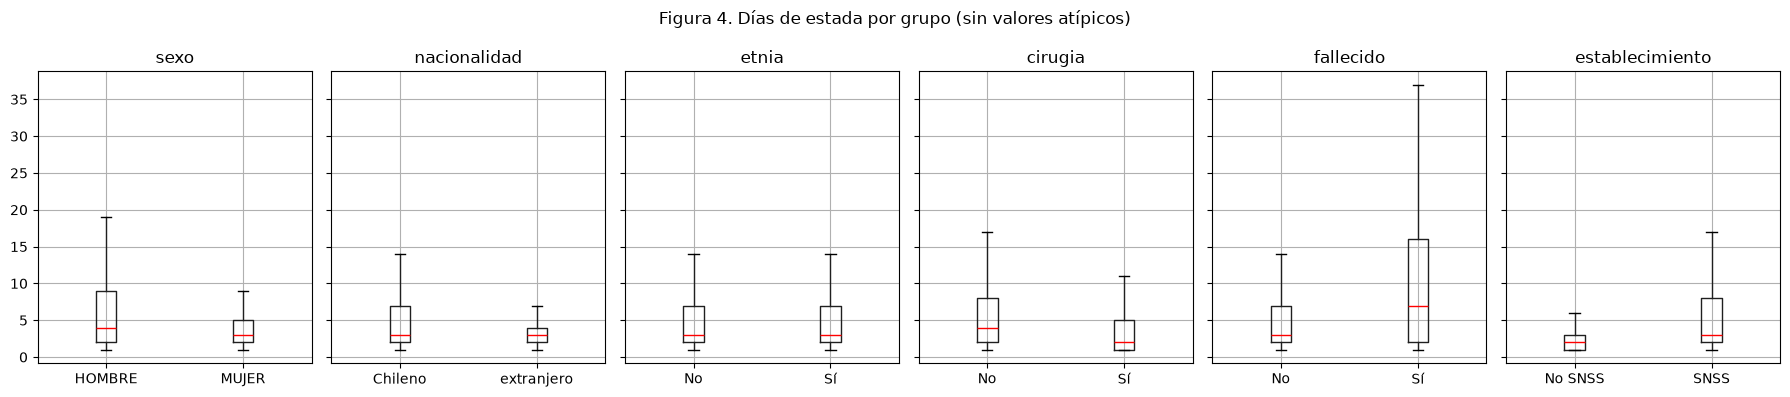

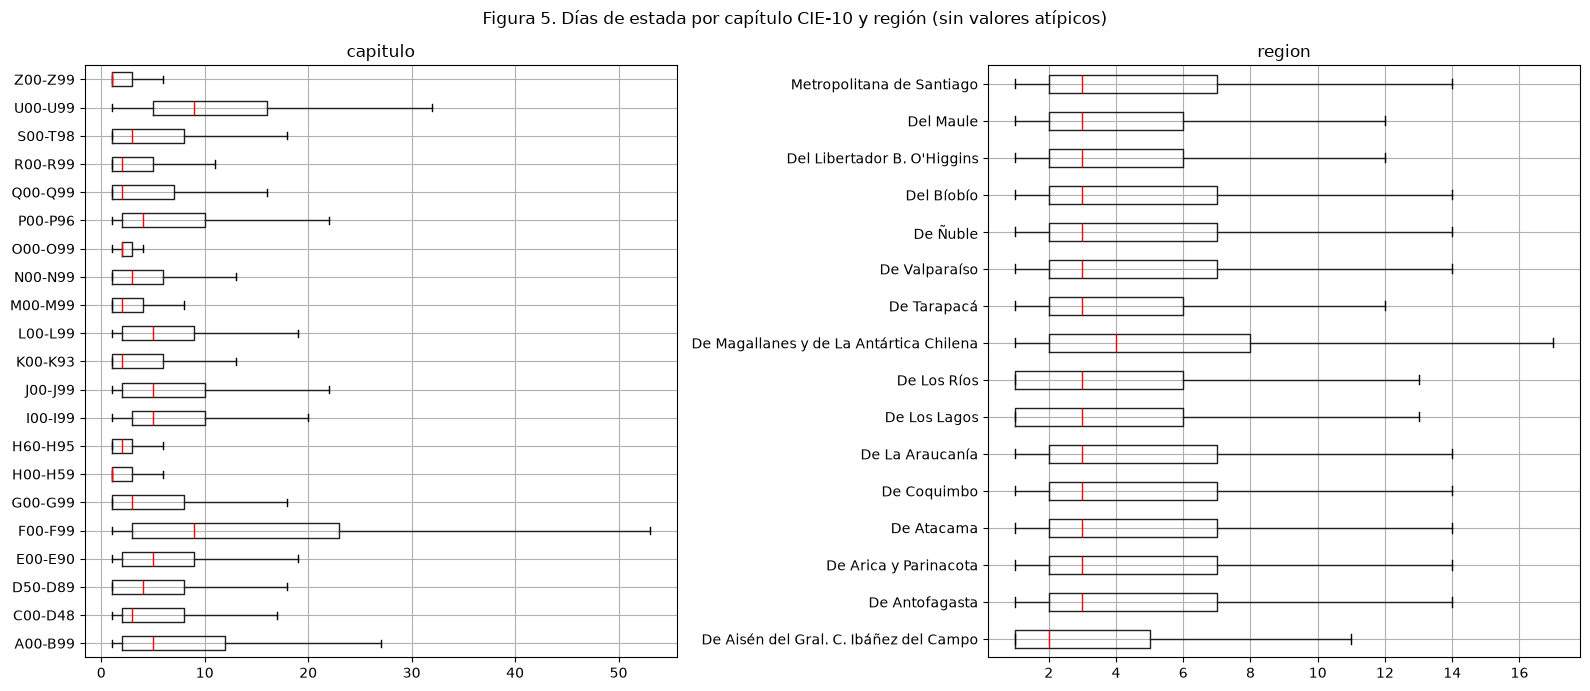

In [11]:
fig, ax = plt.subplots(1, 6, figsize=(18, 4), sharey=True)
for i, var in enumerate(["sexo", "nacionalidad", "etnia", "cirugia", "fallecido", "establecimiento"]):
    df.boxplot(column="dias_estada", by=var, ax=ax[i], showfliers=False, color=dict(medians="red"))
    ax[i].set_title(var)
    ax[i].set_xlabel("")
fig.suptitle("Figura 4. Días de estada por grupo (sin valores atípicos)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for i, var in enumerate(["capitulo", "region"]):
    df.boxplot(column="dias_estada", by=var, ax=ax[i], showfliers=False, vert=False, color=dict(medians="red"))
    ax[i].set_title(var)
    ax[i].set_ylabel("")
fig.suptitle("Figura 5. Días de estada por capítulo CIE-10 y región (sin valores atípicos)")
plt.tight_layout()
plt.show()

Todas las pruebas dan p < 0,001, así que rechazamos H₀ en todos los factores. Con tantos datos eso era esperable, y lo que realmente distingue a un factor de otro es el tamaño del efecto:

| Factor | Efecto | Qué significa |
|---|---|---|
| Establecimiento | r = −0,37 (mediano) | En los establecimientos SNSS las estadías son más largas que en los no SNSS |
| Capítulo CIE-10 | ε² = 0,12 (mediano) | La mediana va de 1 día (controles, ojo) a 9 días (trastornos mentales, COVID-19) |
| Condición de egreso | r = −0,29 (pequeño) | Los pacientes que fallecen estuvieron más tiempo (mediana de 7 contra 3 días) |
| Cirugía | r = 0,22 (pequeño) | Sin cirugía se está más tiempo (mediana de 4 contra 2 días) |
| Sexo | r = 0,14 (pequeño) | Los hombres están un día más (4 contra 3); los partos, que son cortos, bajan la mediana de las mujeres |
| Nacionalidad, etnia, región | Despreciable | Salen significativos solo por el tamaño de la muestra |

En el post-hoc difieren 202 de los 210 pares de capítulos y 104 de los 120 pares de regiones. En la región, eso sí, el efecto global sigue siendo despreciable (ε² = 0,002): hay diferencias entre regiones, pero son muy chicas.

### 5.4 Categórica vs. categórica: estadía prolongada según cada factor

Aplicamos chi-cuadrado de independencia entre cada factor y la estadía prolongada (Sí/No). La edad entra con sus 11 tramos, y la fuerza de la asociación la medimos con la V de Cramér.

- H₀: el factor y la estadía prolongada son independientes.
- H₁: están asociados.

El chi-cuadrado exige frecuencias esperadas de al menos 5. Si en una tabla 2×2 no se cumpliera, usaríamos el test exacto de Fisher.

In [12]:
filas = []
for var in ["tramo_edad", "sexo", "nacionalidad", "etnia", "capitulo", "cirugia", "fallecido", "establecimiento", "region"]:
    tabla = pd.crosstab(df[var], df["prolongada"])
    chi2, p, gl, esperadas = stats.chi2_contingency(tabla)
    v = np.sqrt(chi2 / (len(df) * (min(tabla.shape) - 1)))
    pct = 100 * tabla["Sí"] / tabla.sum(axis=1)
    filas.append({"variable": var, "chi²": round(chi2), "gl": gl, "valor-p": p, "V de Cramér": round(v, 3),
                  "% prolongadas (mín - máx)": f"{pct.min():.1f} - {pct.max():.1f}",
                  "frec. esperada mínima": round(esperadas.min())})
pd.DataFrame(filas)

,variable,chi²,gl,valor-p,V de Cramér,% prolongadas (mín - máx),frec. esperada mínima
0,tramo_edad,26265,10,0.000000e+00,0.165,3.5 - 15.4,1408
1,sexo,10332,1,0.000000e+00,0.103,6.9 - 13.1,36376
2,nacionalidad,642,1,1.294187e-141,0.026,5.7 - 9.5,3599
3,etnia,14,1,1.932279e-04,0.004,8.6 - 9.4,1987
4,capitulo,60840,20,0.000000e+00,0.251,0.9 - 35.6,175
5,cirugia,2749,1,0.000000e+00,0.053,7.4 - 10.6,34007
6,fallecido,11515,1,0.000000e+00,0.109,8.8 - 25.3,3506
7,establecimiento,6897,1,0.000000e+00,0.084,4.2 - 10.6,16504
8,region,2343,15,0.000000e+00,0.049,6.6 - 10.9,674


Como ejemplo, esta es la tabla de contingencia entre establecimiento y estadía prolongada:

In [13]:
tabla = pd.crosstab(df["establecimiento"], df["prolongada"], margins=True)
tabla["% prolongadas"] = (100 * tabla["Sí"] / tabla["All"]).round(1)
tabla

prolongada,No,Sí,All,% prolongadas
establecimiento,,,,
No SNSS,168437,7316,175753,4.2
SNSS,708752,83593,792345,10.6
All,877189,90909,968098,9.4


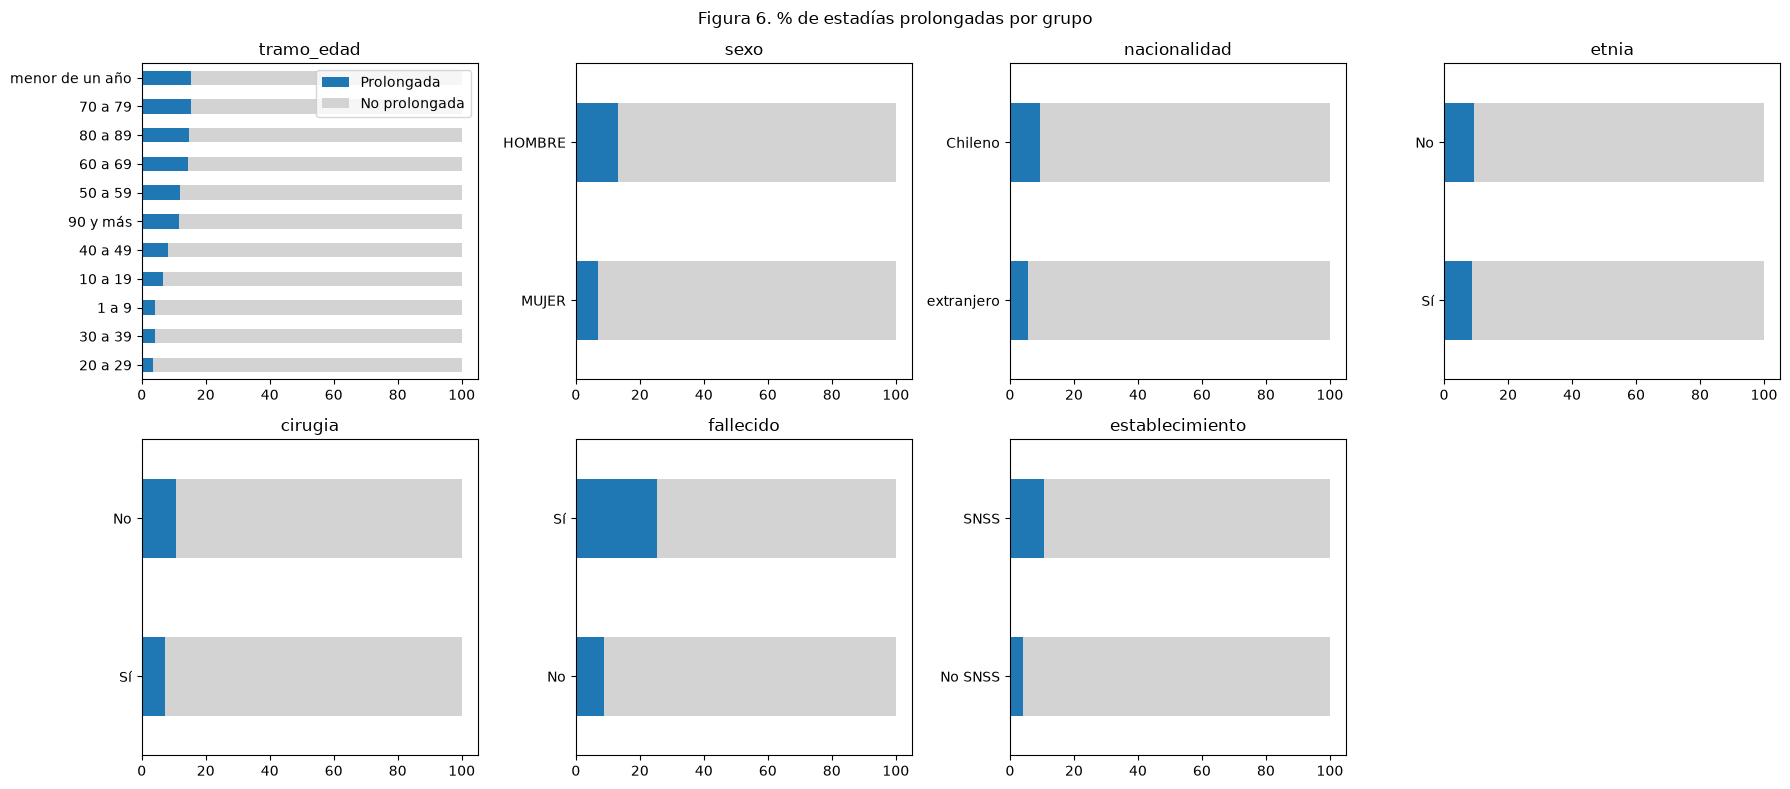

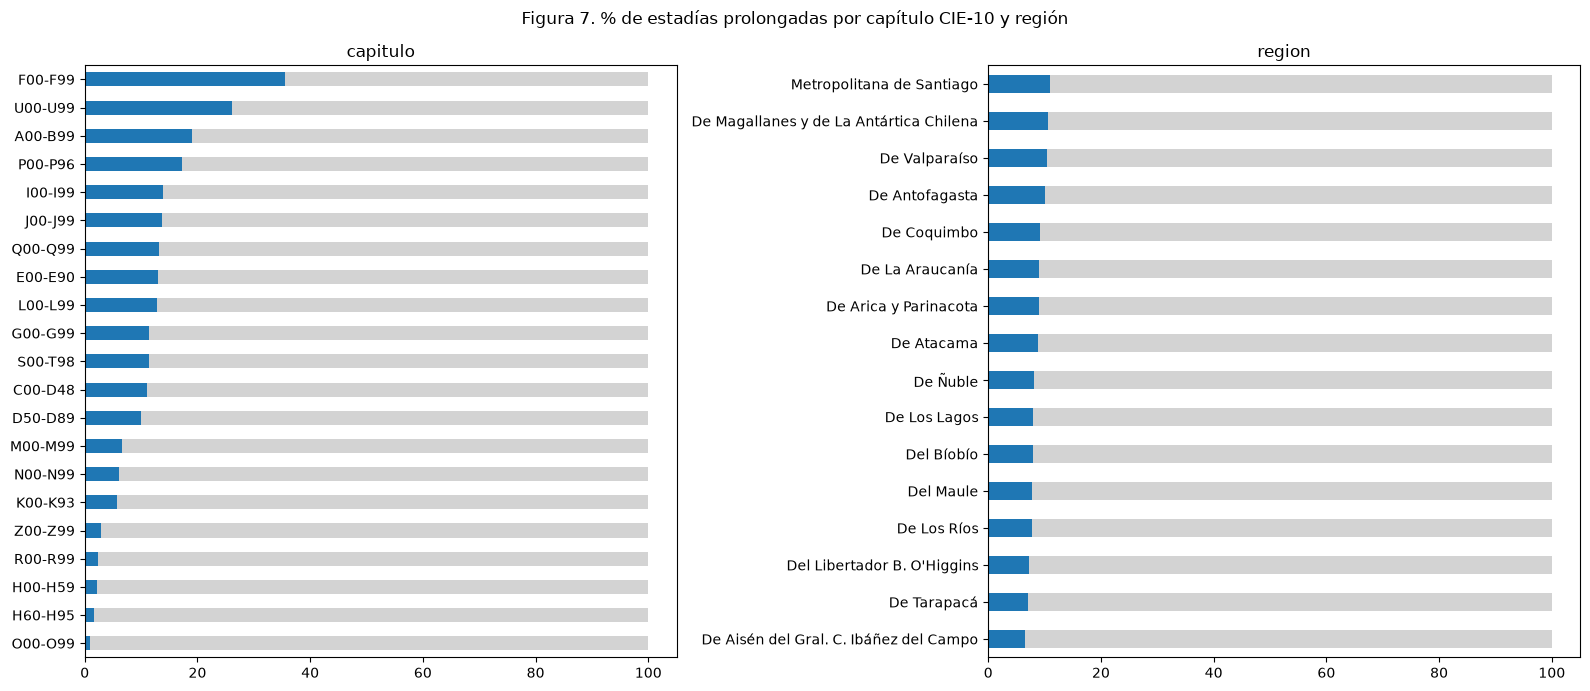

In [14]:
def barras(var, ax):
    pct = pd.crosstab(df[var], df["prolongada"], normalize="index")[["Sí", "No"]] * 100
    pct.sort_values("Sí").plot(kind="barh", stacked=True, ax=ax, legend=False, color=["tab:blue", "lightgray"])
    ax.set_title(var)
    ax.set_ylabel("")

fig, ax = plt.subplots(2, 4, figsize=(18, 8))
for i, var in enumerate(["tramo_edad", "sexo", "nacionalidad", "etnia", "cirugia", "fallecido", "establecimiento"]):
    barras(var, ax.flat[i])
ax.flat[7].axis("off")
ax.flat[0].legend(["Prolongada", "No prolongada"])
fig.suptitle("Figura 6. % de estadías prolongadas por grupo")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
barras("capitulo", ax[0])
barras("region", ax[1])
fig.suptitle("Figura 7. % de estadías prolongadas por capítulo CIE-10 y región")
plt.tight_layout()
plt.show()

Todas las frecuencias esperadas superan 5 (la menor es 175), así que el chi-cuadrado es válido. Todas las pruebas dan p < 0,001 y rechazamos H₀ en todos los factores, pero con fuerzas muy distintas:

| Factor | V de Cramér | Qué significa |
|---|---|---|
| Capítulo CIE-10 | 0,25 (pequeño) | De 0,9 % de prolongadas en partos a 35,6 % en trastornos mentales |
| Tramo de edad | 0,17 (pequeño) | Forma de U: 15,4 % en menores de un año, 3,5 % entre 20 y 29 años y 15,4 % entre 70 y 79 |
| Condición de egreso | 0,11 (pequeño) | 25,3 % en fallecidos y 8,8 % en vivos |
| Sexo | 0,10 (pequeño) | 13,1 % en hombres y 6,9 % en mujeres |
| Establecimiento | 0,08 (despreciable) | 10,6 % en SNSS y 4,2 % fuera del SNSS |
| Cirugía, región, nacionalidad, etnia | < 0,06 (despreciable) | Diferencias de pocos puntos porcentuales |

### 5.5 Tabla resumen

| Variable 1 | Variable 2 | Test aplicado | Valor-p | Conclusión |
|---|---|---|---|---|
| Días de estada | Normalidad | Shapiro-Wilk, Lilliefors, Anderson-Darling | < 0,001 | No es normal: usamos pruebas no paramétricas |
| Edad | Normalidad | Shapiro-Wilk, Lilliefors, Anderson-Darling | < 0,001 | No es normal: usamos pruebas no paramétricas |
| Edad | Días de estada | Spearman | < 0,001 | Más edad, algo más de días (ρ = 0,25, pequeño) |
| Sexo | Días de estada | Mann-Whitney U | < 0,001 | Hombres con estadías más largas (r = 0,14, pequeño) |
| Nacionalidad | Días de estada | Mann-Whitney U | < 0,001 | Efecto despreciable (r = 0,06) |
| Etnia | Días de estada | Mann-Whitney U | < 0,001 | Efecto despreciable (r = −0,02) |
| Cirugía | Días de estada | Mann-Whitney U | < 0,001 | Sin cirugía, estadías más largas (r = 0,22, pequeño) |
| Condición de egreso | Días de estada | Mann-Whitney U | < 0,001 | Fallecidos con estadías más largas (r = −0,29, pequeño) |
| Establecimiento | Días de estada | Mann-Whitney U | < 0,001 | SNSS con estadías más largas (r = −0,37, mediano) |
| Capítulo CIE-10 | Días de estada | Kruskal-Wallis + post-hoc | < 0,001 | Mediana de 1 a 9 días según capítulo (ε² = 0,12, mediano) |
| Región | Días de estada | Kruskal-Wallis + post-hoc | < 0,001 | Efecto despreciable (ε² = 0,002) |
| Tramo de edad | Estadía prolongada | Chi-cuadrado | < 0,001 | Forma de U (V = 0,17, pequeño) |
| Sexo | Estadía prolongada | Chi-cuadrado | < 0,001 | 13,1 % hombres vs. 6,9 % mujeres (V = 0,10, pequeño) |
| Nacionalidad | Estadía prolongada | Chi-cuadrado | < 0,001 | Efecto despreciable (V = 0,03) |
| Etnia | Estadía prolongada | Chi-cuadrado | < 0,001 | Efecto despreciable (V = 0,004) |
| Capítulo CIE-10 | Estadía prolongada | Chi-cuadrado | < 0,001 | De 0,9 % a 35,6 % (V = 0,25, pequeño) |
| Cirugía | Estadía prolongada | Chi-cuadrado | < 0,001 | Efecto despreciable (V = 0,05) |
| Condición de egreso | Estadía prolongada | Chi-cuadrado | < 0,001 | 25,3 % fallecidos vs. 8,8 % vivos (V = 0,11, pequeño) |
| Establecimiento | Estadía prolongada | Chi-cuadrado | < 0,001 | 10,6 % vs. 4,2 % (V = 0,08, despreciable) |
| Región | Estadía prolongada | Chi-cuadrado | < 0,001 | Efecto despreciable (V = 0,05) |
| `DIAG2` | Capítulo S00-T98 | Chi-cuadrado | < 0,001 | Redundantes (V = 1,00): se descarta `DIAG2` (5.6) |

### 5.6 Selección de variables para la regresión múltiple

Las pruebas de 5.2 a 5.4 son de a pares y todas rechazan H₀, así que no sirven para decidir qué variables usar: con casi un millón de egresos, hasta un efecto de V = 0,004 sale significativo. Para elegir, primero comprobamos con los datos las dos redundancias de la metodología: que `DIAG2` repite el capítulo S00-T98 y que cada comuna pertenece a una sola región.

Después ajustamos una regresión lineal de log(días) con las 9 candidatas y aplicamos eliminación hacia atrás según el BIC (Schwarz, 1978):

BIC = n · ln(SCR / n) + k · ln(n)

donde SCR es la suma de cuadrados de los residuos y k el número de coeficientes. En cada paso sacamos la variable cuya salida más baja el BIC, y paramos cuando sacar cualquiera lo sube. Lo que nos sirve del BIC es que cada coeficiente cuesta ln(n) = ln(968.098) ≈ 13,8. Para una variable de un coeficiente, eso equivale a exigir un F parcial mayor que 13,8, en vez del 3,84 que pide p < 0,05 (Raftery, 1995). La edad entra junto con edad², porque en 5.4 vimos que su relación con la estadía tiene forma de U. En cada paso informamos también el F parcial, que contrasta H₀: todos los coeficientes de la variable valen 0, dado el resto del modelo.

Por último, revisamos con el VIF que las variables que quedan no se repitan entre sí. Un VIF sobre 10 indicaría un problema.

In [15]:
import statsmodels.api as sm
from patsy import dmatrices
from statsmodels.stats.outliers_influence import variance_inflation_factor

tabla = pd.crosstab(df["capitulo"] == "S00-T98", df["DIAG2"].notna(), rownames=["capítulo S00-T98"], colnames=["tiene DIAG2"])
chi2, p, gl, esperadas = stats.chi2_contingency(tabla)
print(tabla)
print("V de Cramér DIAG2 vs. capítulo S00-T98:", round(np.sqrt(chi2 / len(df)), 3), "| valor-p:", p)
print("Comunas que aparecen en más de una región:", (df.groupby("COMUNA_RESIDENCIA")["REGION_RESIDENCIA"].nunique() > 1).sum())

df["log_dias"] = np.log(df["dias_estada"])
df["edad_c"] = df["edad"] - 50  # centrada para que edad y edad² no queden colineales
formula = ("log_dias ~ edad_c + I(edad_c**2) + C(sexo) + C(nacionalidad) + C(etnia) + C(capitulo, Treatment('O00-O99'))"
           " + C(cirugia) + C(fallecido) + C(establecimiento) + C(region, Treatment('Metropolitana de Santiago'))")
y, X = dmatrices(formula, df, return_type="dataframe")
candidatas = ["edad", "sexo", "nacionalidad", "etnia", "capitulo", "cirugia", "fallecido", "establecimiento", "region"]
columnas = {v: [c for c in X.columns if c.startswith((f"C({v})", f"C({v},"))] for v in candidatas}
columnas["edad"] = ["edad_c", "I(edad_c ** 2)"]

def ajustar(variables):
    return sm.OLS(y, X[["Intercept"] + [c for v in variables for c in columnas[v]]]).fit()

seleccion = list(candidatas)
modelo = ajustar(seleccion)
pasos = []
while True:
    filas = []
    for var in seleccion:
        sin_var = ajustar([v for v in seleccion if v != var])
        f, p, gl = modelo.compare_f_test(sin_var)
        filas.append({"paso": len(pasos) + 1, "variable": var, "Δ BIC al sacarla": round(sin_var.bic - modelo.bic, 1),
                      "F parcial": round(f, 2), "gl": int(gl), "valor-p": p,
                      "Δ R² ajustado (puntos)": round(100 * (modelo.rsquared_adj - sin_var.rsquared_adj), 3)})
    paso = pd.DataFrame(filas).sort_values("Δ BIC al sacarla")
    pasos.append(paso)
    peor = paso.iloc[0]
    if peor["Δ BIC al sacarla"] >= 0:
        break
    print(f"Paso {len(pasos)}: sale {peor['variable']} (el BIC baja {-peor['Δ BIC al sacarla']})")
    seleccion.remove(peor["variable"])
    modelo = ajustar(seleccion)

print(f"Paso {len(pasos)}: sacar cualquier variable sube el BIC. Penalización por coeficiente: ln(n) = {np.log(len(df)):.2f}")
print("Variables seleccionadas:", ", ".join(seleccion), "| R² ajustado:", round(modelo.rsquared_adj, 3))
Xs = X[["Intercept"] + [c for v in seleccion for c in columnas[v]]].sample(100000, random_state=1)
vif = [variance_inflation_factor(Xs.values, i) for i in range(1, Xs.shape[1])]
print("VIF máximo:", round(max(vif), 2))
pasos[0]

tiene DIAG2        False  True 
capítulo S00-T98               
False             872823     74
True                   0  95201
V de Cramér DIAG2 vs. capítulo S00-T98: 1.0 | valor-p: 0.0
Comunas que aparecen en más de una región: 0


Paso 1: sale nacionalidad (el BIC baja 11.2)


Paso 2: sale etnia (el BIC baja 1.4)


Paso 3: sacar cualquier variable sube el BIC. Penalización por coeficiente: ln(n) = 13.78
Variables seleccionadas: edad, sexo, capitulo, cirugia, fallecido, establecimiento, region | R² ajustado: 0.198


VIF máximo: 1.79


,paso,variable,Δ BIC al sacarla,F parcial,gl,valor-p,Δ R² ajustado (puntos)
2,1,nacionalidad,-11.2,2.57,1,1.089500e-01,0.000
3,1,etnia,-1.5,12.25,1,4.655593e-04,0.001
6,1,fallecido,124.9,138.64,1,5.302995e-32,0.011
5,1,cirugia,144.8,158.58,1,2.328440e-36,0.013
1,1,sexo,2515.3,2532.23,1,0.000000e+00,0.210
8,1,region,4301.2,301.22,15,0.000000e+00,0.373
0,1,edad,34119.6,17377.49,2,0.000000e+00,2.879
7,1,establecimiento,40073.8,40927.25,1,0.000000e+00,3.391
4,1,capitulo,74020.6,3860.90,20,0.000000e+00,6.395


La tabla muestra el primer paso, con las 9 candidatas. Dos tienen un Δ BIC negativo, es decir, el modelo mejora al sacarlas. Nacionalidad sale en el primer paso: su F parcial es 2,57 (p = 0,11), así que ni siquiera es significativa una vez que se controla por las demás variables. Etnia sale en el segundo, y con ella sí hay que explicar algo más, porque su F parcial de 12,2 es significativo (p < 0,001). No llega al umbral de 13,8 del BIC, y su aporte al R² es de apenas 0,001 puntos, así que no justifica un coeficiente más. En el tercer paso, sacar cualquiera de las siete restantes sube el BIC, y ahí termina la selección.

**Tabla 5.6.** Resultado de la selección (valores del primer paso, con las 9 candidatas)

| Variable | Δ BIC al sacarla | F parcial | Δ R² ajustado (puntos) | Decisión |
|---|---|---|---|---|
| Capítulo CIE-10 | 74.021 | 3.861 (gl = 20) | 6,40 | Entra |
| Establecimiento | 40.074 | 40.927 | 3,39 | Entra |
| Edad (edad y edad²) | 34.120 | 17.377 (gl = 2) | 2,88 | Entra |
| Región | 4.301 | 301 (gl = 15) | 0,37 | Entra |
| Sexo | 2.515 | 2.532 | 0,21 | Entra |
| Cirugía | 145 | 159 | 0,01 | Entra |
| Condición de egreso | 125 | 139 | 0,01 | Entra |
| Etnia | −1,5 | 12,2 (p < 0,001) | 0,001 | Sale (paso 2) |
| Nacionalidad | −11,2 | 2,6 (p = 0,11) | 0 | Sale (paso 1) |

Con la región pasa lo contrario que con etnia. De a pares su efecto era despreciable (ε² = 0,002), pero dentro del modelo aporta más que el sexo: una vez que se controla por diagnóstico, edad y establecimiento, aparecen diferencias entre regiones que de a pares no se veían. La redundancia también queda confirmada con los datos: `DIAG2` tiene una V de Cramér de 1,00 contra el capítulo S00-T98, y ninguna comuna aparece en más de una región. El VIF más alto entre las variables seleccionadas es 1,8, lejos de 10.

La regresión del Avance 2 usará entonces 7 variables explicativas (capítulo CIE-10, establecimiento, edad, región, sexo, cirugía y condición de egreso) y las 2 variables respuesta, 9 columnas en total. Con ellas el modelo explica el 19,8 % de la variabilidad del logaritmo de los días.

### Conclusión

Todas las pruebas de a pares rechazan H₀, así que rechazamos la hipótesis nula general. Si miramos el tamaño del efecto y la selección de 5.6, el resultado por grupo de factores es este:

- H1a (clínicos) se cumple. El capítulo CIE-10 es el factor más importante. La condición de egreso tiene un efecto pequeño. La cirugía cambia los días, pero casi no cambia la proporción de estadías prolongadas. Las tres entran a la regresión.
- H1b (demográficos) se cumple para edad y sexo, con efectos pequeños, y las dos entran al modelo. Nacionalidad y etnia no tienen un efecto relevante y el BIC las deja fuera.
- H1c (sistema de salud) se cumple para el tipo de establecimiento, con un efecto mediano sobre los días. La región tiene un efecto despreciable de a pares, pero aporta al controlar por las demás variables, así que también entra.

La regresión múltiple del Avance 2 va a mostrar cuánto pesa cada factor cuando se consideran todos juntos, por ejemplo si la diferencia entre hombres y mujeres se mantiene al controlar por diagnóstico.

## Referencias

1. Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.
2. Fetter, R. B., Shin, Y., Freeman, J. L., Averill, R. F., & Thompson, J. D. (1980). Case mix definition by diagnosis-related groups. *Medical Care, 18*(2 Suppl.), 1–53.
3. Freitas, A., Silva-Costa, T., Lopes, F., Garcia-Lema, I., Teixeira-Pinto, A., Brazdil, P., & Costa-Pereira, A. (2012). Factors influencing hospital high length of stay outliers. *BMC Health Services Research, 12*, 265. https://doi.org/10.1186/1472-6963-12-265
4. Kerby, D. S. (2014). The simple difference formula: An approach to teaching nonparametric correlation. *Comprehensive Psychology, 3*, 11.IT.3.1. https://doi.org/10.2466/11.IT.3.1
5. Lequertier, V., Wang, T., Fondrevelle, J., Augusto, V., & Duclos, A. (2021). Hospital length of stay prediction methods: A systematic review. *Medical Care, 59*(10), 929–938. https://doi.org/10.1097/MLR.0000000000001596
6. Lin, M., Lucas, H. C., & Shmueli, G. (2013). Too big to fail: Large samples and the p-value problem. *Information Systems Research, 24*(4), 906–917. https://doi.org/10.1287/isre.2013.0480
7. Olivares-Tirado, P. (2020). *Hospitalización social en adultos mayores en el sistema de salud de Chile* [Documento de trabajo]. Superintendencia de Salud. https://www.superdesalud.gob.cl/biblioteca-digital/hospitalizacion-social-en-adultos-mayores-en-el-sistema-de-salud-de-chile/
8. Raftery, A. E. (1995). Bayesian model selection in social research. *Sociological Methodology, 25*, 111–163. https://doi.org/10.2307/271063
9. Schwarz, G. (1978). Estimating the dimension of a model. *The Annals of Statistics, 6*(2), 461–464. https://doi.org/10.1214/aos/1176344136